# Fase 3 — Análisis predictivo · Actividades 1 a 6

**Proyecto:** Brecha de la educación y su impacto en la movilidad laboral y salarios (Paraguay).
**Fuente:** Encuesta Permanente de Hogares Continua (EPHC) anual 2025, INE (`REG02_EPHC_ANUAL_2025.csv`).
**Pregunta de investigación (Fase 1):** ¿De qué manera el nivel educativo impacta en los ingresos laborales de la Población Económicamente Activa (PEA) en Paraguay durante el año 2025?

## Alcance de esta fase
1. **Definir la tarea predictiva** (tipo de tarea, variable objetivo y vínculo con un objetivo específico).
2. **Preparar los datos para el modelado** (codificación, escalado, desbalance, selección de variables).
3. **Particionar los datos** (entrenamiento y prueba, con semilla fijada).
4. **Establecer una línea base** (modelo trivial que todo modelo posterior debe superar).
5. **Entrenar modelos de tres familias** (lineal, árboles, boosting) y documentar sus hiperparámetros.
6. **Validación cruzada y ajuste de hiperparámetros** (sin tocar el conjunto de prueba).

AGREGAR actividades 7 a 9 en este mismo notebook.

## Para ejecutar
*Restart session & Run All*. Si `data/REG02_EPHC_ANUAL_2025.csv` no existe, el notebook lo descarga del INE. Todas las rutas son relativas, la semilla es fija (`SEMILLA = 42`) y no se edita ningún dato a mano. Las búsquedas de hiperparámetros de la Actividad 6 pueden tardar varios minutos.

# 0. Configuración

In [1]:
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Semilla única para todo el notebook (partición, y más adelante CV y modelos).
SEMILLA = 42
np.random.seed(SEMILLA)

# Rutas relativas a la raíz del repositorio.
DIR_DATOS = Path("data")
DIR_SALIDA = Path("output") / "fase3"
for d in (DIR_DATOS, DIR_SALIDA):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 50)

# 1. Datos de partida: reconstrucción del conjunto limpio de la Fase 2

Para que este notebook sea reproducible por sí solo, se parte del archivo **original** y se repiten, de forma compacta, los pasos de la Parte A de la Fase 2 **solo para las columnas que usa el modelado**. No se introduce ninguna decisión nueva en esta sección:

- Lectura del CSV (separador `;`, UTF-8 con BOM, todo como texto), valores en blanco y **coma decimal → punto** (corrección de la Fase 2 sobre `e01aimde`).
- Recodificación de códigos de "no responde / sin dato" a faltante (incluye `ED0504` en {8888, 9999} e `informalidad == 9`, correcciones de la Fase 2).
- Controles de dominio: ingresos negativos y horas fuera de [0, 168] pasan a faltante.
- `estrato_educativo` con el corte corregido (terciaria = códigos 2001-2406; los 1001-1900 quedan sin clasificar).
- Población de análisis: **ocupados (`PEAA == 1`) de 18 a 60 años** (24.379 registros en la Fase 2).
- Mismo identificador `ID_PERSONA` y mismos nombres de columna que la Fase 2.

In [ ]:
URL_EPHC = "https://www.ine.gov.py/microdatos/register/EPHC-ANUAL/EPHC_2025_ANUAL/REG02_EPHC_ANUAL_2025.csv"
RUTA_CSV = DIR_DATOS / "REG02_EPHC_ANUAL_2025.csv"

if RUTA_CSV.exists():
    print(f"Se usa el archivo existente: {RUTA_CSV}")
else:
    print(f"Descargando {RUTA_CSV.name} desde el INE...")
    with requests.get(URL_EPHC, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(RUTA_CSV, "wb") as f:
            for trozo in r.iter_content(chunk_size=1 << 20):
                f.write(trozo)
    print("Descarga completada.")

Descargando REG02_EPHC_ANUAL_2025.csv desde el INE...
Descarga completada.


In [4]:
def clave(nombre):
    """Normaliza un nombre de columna (sin tildes, minúsculas, sin espacios) para
    encontrarlo en el archivo original aunque cambien mayúsculas/minúsculas."""
    s = unicodedata.normalize("NFKD", str(nombre).strip())
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    return re.sub(r"\s+", "", s).casefold()

# Columna original -> nombre usado en la Fase 2 (mismo diccionario de reetiquetado).
COLUMNAS = {
    "UPM": "ID_CONGLOMERADO_UPM",
    "NVIVI": "ID_VIVIENDA_NVIVI",
    "NHOGA": "ID_HOGAR_NHOGA",
    "FACTOR": "FACTOR_EXPANSION",
    "AREA": "AREA_URBANA_RURAL",
    "P02": "EDAD",
    "P06": "SEXO",
    "añoest": "ANIOS_ESTUDIO",
    "ED0504": "NIVEL_GRADO_MAX_APROBADO",
    "PEAA": "CONDICION_ACTIVIDAD",
    "CATE_PEA": "CATEGORIA_OCUPACIONAL",
    "informalidad": "INFORMALIDAD",
    "e01aimde": "INGRESO_HABITUAL_PRINCIPAL",
    "HORAB": "HORAS_SEMANALES_PRINCIPAL",
}

cabecera = pd.read_csv(RUTA_CSV, sep=";", encoding="utf-8-sig", nrows=0).columns
mapa_real = {clave(c): c for c in cabecera}
faltan = [o for o in COLUMNAS if clave(o) not in mapa_real]
if faltan:
    raise KeyError(f"No se encontraron en el archivo original: {faltan}")

renombrar = {mapa_real[clave(o)]: nuevo for o, nuevo in COLUMNAS.items()}
df_raw = pd.read_csv(RUTA_CSV, sep=";", encoding="utf-8-sig", dtype=str,
                     usecols=list(renombrar), low_memory=False).rename(columns=renombrar)
df_raw = df_raw[list(COLUMNAS.values())]
print(f"Archivo original: {df_raw.shape[0]:,} filas | columnas usadas: {df_raw.shape[1]}")

Archivo original: 55,934 filas | columnas usadas: 14


In [5]:
df = df_raw.copy()

# 1) Blancos (la EPHC usa " ") y coma decimal -> punto, y conversión a numérico.
for c in df.columns:
    df[c] = pd.to_numeric(df[c].str.strip().str.replace(",", ".", regex=False), errors="coerce")

# 2) Códigos de "no responde / sin dato" -> faltante.
CODIGOS_NR = {
    "ANIOS_ESTUDIO": [99],
    "CONDICION_ACTIVIDAD": [9],
    "HORAS_SEMANALES_PRINCIPAL": [999],
    "INFORMALIDAD": [9],
    "INGRESO_HABITUAL_PRINCIPAL": [99999999999],
    "NIVEL_GRADO_MAX_APROBADO": [8888, 9999],
}
for v, codigos in CODIGOS_NR.items():
    df.loc[df[v].isin(codigos), v] = np.nan

# 3) Controles de dominio.
df.loc[df["INGRESO_HABITUAL_PRINCIPAL"].lt(0), "INGRESO_HABITUAL_PRINCIPAL"] = np.nan
df.loc[~df["HORAS_SEMANALES_PRINCIPAL"].between(0, 168) & df["HORAS_SEMANALES_PRINCIPAL"].notna(),
       "HORAS_SEMANALES_PRINCIPAL"] = np.nan

# 4) estrato_educativo (corte corregido en la Fase 2).
e = df["NIVEL_GRADO_MAX_APROBADO"]
condiciones = [
    e.eq(0) | e.between(101, 112) | e.between(210, 212) | e.between(301, 306) | e.between(407, 409),
    e.between(501, 503) | e.between(604, 607) | e.between(704, 706) | e.eq(803) | e.between(901, 903),
    e.between(2001, 2406),
]
etiquetas = ["sin/básica", "media", "terciaria/universitaria"]
df["estrato_educativo"] = pd.Series(np.select(condiciones, etiquetas, default=""), index=df.index).replace("", np.nan)

# 5) Población de análisis: ocupados de 18 a 60 años.
mascara = df["EDAD"].between(18, 60) & df["CONDICION_ACTIVIDAD"].eq(1)
df = df.loc[mascara].reset_index(drop=True)
df.insert(0, "ID_PERSONA", df.index + 1)

# 6) Etiquetas de las categóricas clave (se verifica que los códigos sean los del diccionario).
assert set(df["SEXO"].dropna().unique()) <= {1, 6}, "Códigos inesperados en SEXO"
assert set(df["AREA_URBANA_RURAL"].dropna().unique()) <= {1, 6}, "Códigos inesperados en AREA_URBANA_RURAL"
assert set(df["INFORMALIDAD"].dropna().unique()) <= {1, 2}, "Códigos inesperados en INFORMALIDAD"
df["SEXO_DESC"] = df["SEXO"].map({1: "Hombre", 6: "Mujer"})
df["AREA_DESC"] = df["AREA_URBANA_RURAL"].map({1: "Urbana", 6: "Rural"})
df["INFORMALIDAD_DESC"] = df["INFORMALIDAD"].map({1: "Informal", 2: "Formal"})

N_FASE2 = 24_379
print(f"Población de análisis (ocupados, 18-60 años): {len(df):,} filas")
if len(df) != N_FASE2:
    print(f"AVISO: la Fase 2 reportó {N_FASE2:,} filas; revisar qué paso de la reconstrucción difiere.")
else:
    print("Coincide con el conjunto de la Fase 2.")
df.head()

Población de análisis (ocupados, 18-60 años): 24,379 filas
Coincide con el conjunto de la Fase 2.


,ID_PERSONA,ID_CONGLOMERADO_UPM,ID_VIVIENDA_NVIVI,ID_HOGAR_NHOGA,FACTOR_EXPANSION,AREA_URBANA_RURAL,EDAD,SEXO,ANIOS_ESTUDIO,NIVEL_GRADO_MAX_APROBADO,CONDICION_ACTIVIDAD,CATEGORIA_OCUPACIONAL,INFORMALIDAD,INGRESO_HABITUAL_PRINCIPAL,HORAS_SEMANALES_PRINCIPAL,estrato_educativo,SEXO_DESC,AREA_DESC,INFORMALIDAD_DESC
0,1,14,16,1,138,1,40,1,17.000,"2,405.000",1.000,2.000,2.000,"4,589,338.235",45.000,terciaria/universitaria,Hombre,Urbana,Formal
1,2,14,16,1,138,1,39,6,14.000,"2,402.000",1.000,4.000,1.000,"5,099,264.705",42.000,terciaria/universitaria,Mujer,Urbana,Informal
2,3,14,26,1,183,1,32,1,12.000,903.000,1.000,2.000,2.000,"3,263,529.411",56.000,media,Hombre,Urbana,Formal
3,4,14,26,1,183,1,34,1,17.000,"2,405.000",1.000,1.000,2.000,"4,079,411.764",40.000,terciaria/universitaria,Hombre,Urbana,Formal
4,5,14,35,1,120,1,24,1,12.000,"1,003.000",1.000,2.000,1.000,"3,875,441.176",64.000,NaN,Hombre,Urbana,Informal


# 2. Actividad 1 — Definición de la tarea predictiva

## 2.1 Tarea y variable objetivo

| Elemento | Definición |
|---|---|
| **Tipo de tarea** | **Regresión** supervisada. |
| **Variable objetivo** | `INGRESO_HABITUAL_PRINCIPAL` (`e01aimde` en el archivo original): ingreso laboral habitual mensual de la ocupación principal, en guaraníes. |
| **Escala de modelado** | **Logaritmo natural**: `Y_LOG = ln(INGRESO_HABITUAL_PRINCIPAL)`. Las métricas en guaraníes se obtienen más adelante deshaciendo la transformación. |
| **Unidad de análisis** | Persona ocupada de 18 a 60 años (misma población de la Fase 2). |

## 2.2 Vínculo con los objetivos del proyecto

- **Objetivo específico principal: OE2** — *comparar los ingresos laborales según estrato educativo*. El modelo cuantifica cuánto del ingreso es predecible a partir de la educación (`ANIOS_ESTUDIO`) junto con otras características, y qué lugar ocupa la educación frente a ellas. Eso responde de forma directa la pregunta de investigación.
- **OE4** (disparidades por sexo y área): sexo y área entran como predictores, con la interacción educación × sexo respaldada por la hipótesis H4 de la Fase 2.
- **OE3** (calidad de la ocupación): `INFORMALIDAD` y `CATEGORIA_OCUPACIONAL` entran como variables de calidad del empleo.

## 2.3 Por qué regresión y no clasificación

- El objetivo del proyecto es el **nivel** del ingreso y su relación con la educación; discretizarlo (por ejemplo, "alto/bajo") descartaría información y obligaría a elegir un umbral arbitrario.
- Las hipótesis de la Fase 2 (H1 a H4) comparan **medias** de ingreso, y la propuesta original contemplaba una regresión sobre `log(ingreso)`.
- En regresión no hay clases que balancear (ver Actividad 2). Las métricas exigidas por la guía (§7.2) son **RMSE, MAE, MAPE y R² sobre el conjunto de prueba**, comparadas contra la línea base (Actividad 4).

## 2.4 Por qué el logaritmo

La Fase 1 documentó un ingreso con cola muy larga a la derecha (asimetría ≈ 6,5; máximos de hasta 536 millones de Gs.). Con esa forma, unos pocos casos extremos dominarían el error cuadrático. En escala logarítmica la distribución es mucho más simétrica y los coeficientes se leen como diferencias porcentuales aproximadas, que es la lectura habitual de los retornos de la educación. La celda siguiente lo verifica con los datos.

,n
Personas en la población de análisis,24379
Objetivo faltante,0
Objetivo igual a 0,1606
Objetivo mayor que 0,22773


Ingreso habitual principal (> 0), en Gs.:


,Gs.
count,"22,773.000"
mean,"3,217,777.288"
std,"6,755,649.018"
min,453.512
0.1%,"17,062.032"
1%,"122,299.893"
5%,"400,000.000"
25%,"1,497,840.172"
50%,"2,609,509.516"
75%,"3,512,662.807"


Asimetría del ingreso en Gs.:  44.57
Asimetría del ln(ingreso):     -1.06


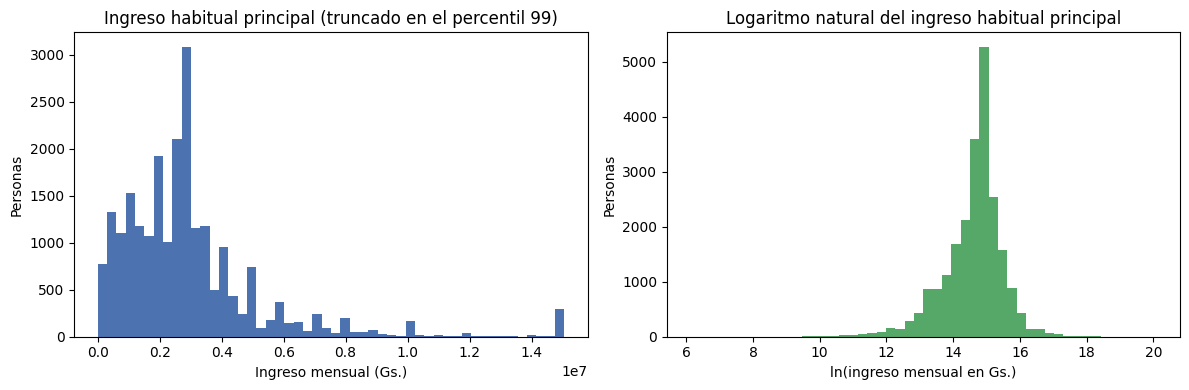

In [6]:
OBJETIVO = "INGRESO_HABITUAL_PRINCIPAL"
y_bruto = df[OBJETIVO]

# Estado del objetivo en la población de la Fase 2.
estado = pd.Series({
    "Personas en la población de análisis": len(y_bruto),
    "Objetivo faltante": int(y_bruto.isna().sum()),
    "Objetivo igual a 0": int(y_bruto.eq(0).sum()),
    "Objetivo mayor que 0": int(y_bruto.gt(0).sum()),
}, name="n")
display(estado.to_frame())

# Distribución del ingreso positivo, en guaraníes y en logaritmo.
pos = y_bruto[y_bruto.gt(0)]
print("Ingreso habitual principal (> 0), en Gs.:")
display(pos.describe(percentiles=[.001, .01, .05, .25, .5, .75, .95, .99, .999]).to_frame("Gs."))
print(f"Asimetría del ingreso en Gs.:  {pos.skew():,.2f}")
print(f"Asimetría del ln(ingreso):     {np.log(pos).skew():,.2f}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(pos.clip(upper=pos.quantile(0.99)), bins=50, color="#4C72B0")
ejes[0].set_title("Ingreso habitual principal (truncado en el percentil 99)")
ejes[0].set_xlabel("Ingreso mensual (Gs.)")
ejes[0].set_ylabel("Personas")
ejes[1].hist(np.log(pos), bins=50, color="#55A868")
ejes[1].set_title("Logaritmo natural del ingreso habitual principal")
ejes[1].set_xlabel("ln(ingreso mensual en Gs.)")
ejes[1].set_ylabel("Personas")
plt.tight_layout()
plt.show()

## 2.5 Tratamiento de los ingresos igual a cero y faltantes del objetivo

La Fase 2 dejó pendiente decidir qué hacer con los casos de ingreso cero antes de transformar. La decisión es:

- **Faltantes del objetivo:** se **excluyen**. No se imputa la variable que se quiere predecir, porque inventaría la respuesta que el modelo debe aprender.
- **Ingreso = 0:** se **excluyen**. El logaritmo no está definido en 0, y la alternativa `ln(1 + ingreso)` fabricaría una masa artificial de observaciones en `ln(1) = 0`, muy alejada del resto. La tabla siguiente muestra cómo se distribuyen estos ceros según `CATEGORIA_OCUPACIONAL`: la Fase 1 ya anticipaba que los trabajadores familiares no remunerados (`CATE_PEA == 5`) no tienen ingreso que comparar.

**Consecuencia para el alcance:** el modelo describe a los **ocupados de 18 a 60 años con ingreso laboral positivo**. Esta restricción adicional debe figurar en las limitaciones y en la conclusión de la Fase 3.

In [7]:
# Cómo se reparten los ingresos iguales a cero por categoría ocupacional.
display(pd.crosstab(df["CATEGORIA_OCUPACIONAL"], y_bruto.eq(0).rename("ingreso_cero"), margins=True))

# Base de modelado: solo ingreso positivo + objetivo en logaritmo.
n_inicial = len(df)
n_faltante = int(df[OBJETIVO].isna().sum())
n_cero = int(df[OBJETIVO].eq(0).sum())

df_modelo = df.loc[df[OBJETIVO].gt(0)].copy().reset_index(drop=True)
df_modelo["Y_LOG"] = np.log(df_modelo[OBJETIVO])

bitacora_objetivo = pd.DataFrame({
    "paso": ["Población de la Fase 2", "Se excluyen faltantes del objetivo",
             "Se excluyen ingresos iguales a 0", "Base de modelado"],
    "filas": [n_inicial, -n_faltante, -n_cero, len(df_modelo)],
})
display(bitacora_objetivo)
assert n_inicial - n_faltante - n_cero == len(df_modelo)

ingreso_cero,False,True,All
CATEGORIA_OCUPACIONAL,,,
1.000,2607,0,2607
2.000,10230,18,10248
3.000,1199,10,1209
4.000,6927,188,7115
5.000,0,1387,1387
6.000,1810,3,1813
All,22773,1606,24379


,paso,filas
0,Población de la Fase 2,24379
1,Se excluyen faltantes del objetivo,0
2,Se excluyen ingresos iguales a 0,-1606
3,Base de modelado,22773


# 3. Actividad 2 — Preparación de los datos para el modelado

## 3.1 Selección de variables fundamentada en las Fases 1 y 2

| Variable | Rol | Fundamento en las fases previas | Decisión |
|---|---|---|---|
| `ANIOS_ESTUDIO` | Educación (variable central) | Fase 1: gradiente educación-ingreso. Fase 2, H3: el ingreso sube en cada estrato (ANOVA y Tukey). Contiene más información que el estrato. | **Incluir** |
| `SEXO` | Predictor | Fase 2, H1 (brecha ≈ 45 %) y H4 (la brecha educativa difiere por sexo). | **Incluir**, más la interacción `ANIOS_ESTUDIO × SEXO` |
| `AREA` (urbana/rural) | Predictor | Fase 2, H2 (brecha ≈ 39 %). La interacción educación × área quedó como hipótesis pendiente. | **Incluir**, más `ANIOS_ESTUDIO × AREA` (exploratoria) |
| `EDAD` | Control | Recomendado en la Fase 2 (proxy de experiencia). Se agrega `EDAD²` para el perfil cóncavo edad-ingreso. | **Incluir** |
| `HORAS_SEMANALES_PRINCIPAL` | Control | Recomendado en la Fase 2: el ingreso mensual depende de la jornada. | **Incluir** |
| `CATEGORIA_OCUPACIONAL` | Control | Recomendado en la Fase 2 (asalariado, cuenta propia, empleador, etc.). | **Incluir** (categórica) |
| `INFORMALIDAD` | Calidad del empleo (OE3) | Hipótesis original de la Fase 1; la Fase 2 no la contrastó. | **Incluir**; su aporte se evaluará con la importancia de variables (Actividad 9) |
| `INGRESO_*` secundarios, otros y declarados | — | Son componentes o versiones del propio objetivo. | **Excluir** (fuga de información) |
| `estrato_educativo` | — | Deriva de `NIVEL_GRADO_MAX_APROBADO`, igual que `ANIOS_ESTUDIO`, pero con menos información. | **Excluir** como predictor; se conserva como metadato para el análisis de errores |
| `ID_*`, `UPM`, `NVIVI`, `NHOGA` | — | Identificadores. | **Excluir** como predictores; se usan solo para agrupar la partición (Actividad 3) |
| `FACTOR_EXPANSION` | — | Peso muestral, no característica de la persona. | **Excluir** como predictor; se conserva como metadato (la Fase 2 señaló que no se ponderó) |
| Rama, ocupación, tamaño del establecimiento | — | No evaluadas en las fases previas. Son canales por los que la educación actúa sobre el ingreso: incluirlas absorbería parte del efecto que se quiere medir. | **Excluir** en esta iteración |
| Demás variables de calidad del empleo (aportes, contrato, RUC, factura, seguros) | — | `INFORMALIDAD` ya las resume; incluirlas duplicaría información. | **Excluir** |

## 3.2 Codificación de variables categóricas

- **Binarias** (`SEXO`, `AREA`, `INFORMALIDAD`): se codifican 0/1 (`SEXO_MUJER`, `AREA_RURAL`, `INFORMAL`).
- **Nominal de varias categorías** (`CATEGORIA_OCUPACIONAL`): *one-hot*, con `handle_unknown="ignore"` para que una categoría ausente en entrenamiento no rompa la predicción. Los faltantes forman su propia categoría `sin_dato`. No se usa codificación ordinal, porque los códigos del INE no tienen orden.

## 3.3 Escalado

Se definen **dos preprocesadores**, porque el escalado solo es necesario según el algoritmo:

- **Lineal** (regresión lineal, Ridge/Lasso): variables numéricas **estandarizadas** (media 0, desvío 1), para que los coeficientes sean comparables y la penalización actúe por igual. Incluye `EDAD²` y las interacciones.
- **Árboles** (Random Forest, Gradient Boosting): **sin escalar**, porque los cortes de los árboles no dependen de la escala. No lleva `EDAD²` ni interacciones, que los árboles aprenden por sí solos.

## 3.4 Desbalance de clases

**No corresponde:** la tarea es de regresión y la variable objetivo es continua, por lo que no hay clases que balancear (no se aplica sobremuestreo ni submuestreo). El equivalente es que train y test tengan la misma distribución del objetivo; se logra en la partición estratificando por cuantiles del ingreso y se verifica en la Actividad 3.

## 3.5 Faltantes y fuga de información

Las imputaciones (mediana para numéricas, moda para binarias, `sin_dato` para categóricas) y el escalado se **ajustan solo con el conjunto de entrenamiento**. Por eso el preprocesador se define aquí, pero se ajusta **después** de la partición. Ajustarlo antes mezclaría información del conjunto de prueba en el entrenamiento. En la validación cruzada (Actividad 6) el preprocesador irá dentro de un `Pipeline`, de modo que se reajuste en cada pliegue.

In [8]:
# Transformaciones sin estado (no aprenden nada de los datos, por lo que no hay fuga de información).
df_modelo["SEXO_MUJER"] = df_modelo["SEXO_DESC"].map({"Mujer": 1, "Hombre": 0})
df_modelo["AREA_RURAL"] = df_modelo["AREA_DESC"].map({"Rural": 1, "Urbana": 0})
df_modelo["INFORMAL"] = df_modelo["INFORMALIDAD_DESC"].map({"Informal": 1, "Formal": 0})

df_modelo["EDAD2"] = df_modelo["EDAD"] ** 2
df_modelo["ANIOS_X_MUJER"] = df_modelo["ANIOS_ESTUDIO"] * df_modelo["SEXO_MUJER"]
df_modelo["ANIOS_X_RURAL"] = df_modelo["ANIOS_ESTUDIO"] * df_modelo["AREA_RURAL"]

# Categoría ocupacional como texto nominal (los faltantes quedan como NaN para imputarse luego).
df_modelo["CATEGORIA_OCUPACIONAL_CAT"] = (
    df_modelo["CATEGORIA_OCUPACIONAL"].round().astype("Int64").astype(str).replace("<NA>", np.nan)
)

# Conjuntos de variables por tipo de preprocesamiento.
NUM_LINEAL = ["ANIOS_ESTUDIO", "EDAD", "EDAD2", "HORAS_SEMANALES_PRINCIPAL", "ANIOS_X_MUJER", "ANIOS_X_RURAL"]
NUM_ARBOLES = ["ANIOS_ESTUDIO", "EDAD", "HORAS_SEMANALES_PRINCIPAL"]
BINARIAS = ["SEXO_MUJER", "AREA_RURAL", "INFORMAL"]
CATEGORICAS = ["CATEGORIA_OCUPACIONAL_CAT"]

CARACTERISTICAS = list(dict.fromkeys(NUM_LINEAL + NUM_ARBOLES + BINARIAS + CATEGORICAS))

def construir_preprocesador(numericas, binarias, categoricas, escalar):
    """ColumnTransformer sin ajustar: imputación (+ escalado opcional) y codificación."""
    pasos_num = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("escalar", StandardScaler()))
    pasos_cat = [
        ("imputar", SimpleImputer(strategy="constant", fill_value="sin_dato")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
    ct = ColumnTransformer(
        [
            ("num", Pipeline(pasos_num), numericas),
            ("bin", SimpleImputer(strategy="most_frequent"), binarias),
            ("cat", Pipeline(pasos_cat), categoricas),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return ct.set_output(transform="pandas")

preprocesador_lineal = construir_preprocesador(NUM_LINEAL, BINARIAS, CATEGORICAS, escalar=True)
preprocesador_arboles = construir_preprocesador(NUM_ARBOLES, BINARIAS, CATEGORICAS, escalar=False)

# Perfil de faltantes de las características (descriptivo; el ajuste de las imputaciones se hace solo con entrenamiento).
faltantes = (df_modelo[CARACTERISTICAS].isna().mean() * 100).round(2).rename("% faltante").to_frame()
faltantes["n faltantes"] = df_modelo[CARACTERISTICAS].isna().sum()
display(faltantes)

,% faltante,n faltantes
ANIOS_ESTUDIO,0.060,13
EDAD,0.000,0
EDAD2,0.000,0
HORAS_SEMANALES_PRINCIPAL,0.020,5
ANIOS_X_MUJER,0.060,13
ANIOS_X_RURAL,0.060,13
SEXO_MUJER,0.000,0
AREA_RURAL,0.000,0
INFORMAL,14.900,3393
CATEGORIA_OCUPACIONAL_CAT,0.000,0


# 4. Actividad 3 — Partición en entrenamiento y prueba

## 4.1 Criterio de partición

**¿Hay componente temporal?** No. La EPHC anual 2025 es un corte transversal y no contiene una fecha de observación (se documentó en la Fase 1, sección 4.7: `P08A` es el año de nacimiento, no un momento de observación). Por eso **no corresponde una partición cronológica**: no existe un "futuro" con el que se pudiera contaminar el entrenamiento.

**Sí hay dependencia entre observaciones, y es el riesgo que hay que controlar.** Las personas de un mismo hogar comparten área, vivienda, entorno y, muchas veces, ocupación e ingresos. La Fase 2 ya señaló esta dependencia. Con una partición aleatoria por persona, miembros del mismo hogar quedarían repartidos entre entrenamiento y prueba, y el modelo "reconocería" al hogar, lo que inflaría artificialmente la métrica de prueba.

**Partición adoptada:**
- **80 % entrenamiento / 20 % prueba**, con `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)`, tomando el primer pliegue como prueba.
- **Agrupada por hogar** (`UPM` + `NVIVI` + `NHOGA`): ningún hogar aparece en ambos conjuntos.
- **Estratificada por deciles de `Y_LOG`**: ambos conjuntos conservan la distribución del ingreso, incluida su cola.
- El conjunto de prueba **no se toca** hasta la evaluación final (Actividad 7). En la validación cruzada de la Actividad 6 se usará `GroupKFold` con los hogares de entrenamiento.

In [9]:
X = df_modelo[CARACTERISTICAS]
y = df_modelo["Y_LOG"]

# Metadatos: no son predictores; se conservan para el análisis de errores y la interpretación.
meta = df_modelo[["ID_PERSONA", OBJETIVO, "estrato_educativo", "SEXO_DESC", "AREA_DESC", "FACTOR_EXPANSION"]]

# Grupo = hogar (UPM + vivienda + hogar).
grupos = (df_modelo["ID_CONGLOMERADO_UPM"].astype(int).astype(str) + "-"
          + df_modelo["ID_VIVIENDA_NVIVI"].astype(int).astype(str) + "-"
          + df_modelo["ID_HOGAR_NHOGA"].astype(int).astype(str))
print(f"Personas: {len(grupos):,} | Hogares distintos: {grupos.nunique():,}")

# Estratos: deciles del objetivo.
estratos = pd.qcut(y, q=10, labels=False, duplicates="drop")

validador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(validador.split(X, estratos, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
meta_train, meta_test = meta.iloc[idx_train], meta.iloc[idx_test]
grupos_train, grupos_test = grupos.iloc[idx_train], grupos.iloc[idx_test]

# Verificaciones de la partición.
assert set(grupos_train).isdisjoint(set(grupos_test)), "Hay hogares en ambos conjuntos"
assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))

print(f"Entrenamiento: {len(X_train):,} personas ({len(X_train)/len(X):.1%}) en {grupos_train.nunique():,} hogares")
print(f"Prueba:        {len(X_test):,} personas ({len(X_test)/len(X):.1%}) en {grupos_test.nunique():,} hogares")
print("Hogares compartidos entre ambos conjuntos: 0")

# Se guarda la partición para reproducirla en las siguientes iteraciones.
particion = pd.DataFrame({
    "ID_PERSONA": meta["ID_PERSONA"].values,
    "conjunto": np.where(np.isin(np.arange(len(X)), idx_test), "prueba", "entrenamiento"),
})
particion.to_csv(DIR_SALIDA / "particion_train_test.csv", index=False)
print(f"Partición guardada en {DIR_SALIDA / 'particion_train_test.csv'}")

Personas: 22,773 | Hogares distintos: 13,586
Entrenamiento: 18,230 personas (80.1%) en 10,867 hogares
Prueba:        4,543 personas (19.9%) en 2,719 hogares
Hogares compartidos entre ambos conjuntos: 0
Partición guardada en output/fase3/particion_train_test.csv


## 4.2 Verificación: ¿train y test son comparables?

Se comparan la distribución del objetivo y la composición por sexo, área, informalidad y estrato educativo. Se espera que las diferencias sean pequeñas; si no lo fueran, habría que revisar la partición antes de modelar.

,Entrenamiento,Prueba,Diferencia (prueba - entrenamiento)
n,"18,230.000","4,543.000","-13,687.000"
Y_LOG media,14.604,14.599,-0.005
Y_LOG desvío,0.909,0.931,0.022
Y_LOG p10,13.454,13.455,0.001
Y_LOG mediana,14.771,14.786,0.015
Y_LOG p90,15.528,15.516,-0.012
Ingreso mediano (Gs.),"2,600,000.000","2,638,585.786","38,585.786"
% mujeres,42.150,42.571,0.421
% área rural,37.065,36.320,-0.746
% informal,59.952,60.165,0.213


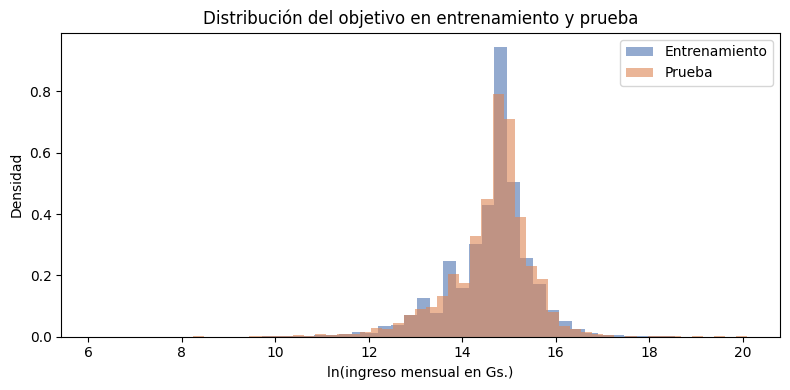

In [10]:
def describir(y_, X_, meta_):
    d = {
        "n": len(y_),
        "Y_LOG media": y_.mean(),
        "Y_LOG desvío": y_.std(),
        "Y_LOG p10": y_.quantile(.10),
        "Y_LOG mediana": y_.median(),
        "Y_LOG p90": y_.quantile(.90),
        "Ingreso mediano (Gs.)": meta_[OBJETIVO].median(),
        "% mujeres": X_["SEXO_MUJER"].mean() * 100,
        "% área rural": X_["AREA_RURAL"].mean() * 100,
        "% informal": X_["INFORMAL"].mean() * 100,
        "Años de estudio (media)": X_["ANIOS_ESTUDIO"].mean(),
        "Edad (media)": X_["EDAD"].mean(),
    }
    for est in ["sin/básica", "media", "terciaria/universitaria"]:
        d[f"% estrato {est}"] = meta_["estrato_educativo"].eq(est).mean() * 100
    return pd.Series(d)

comparacion = pd.DataFrame({
    "Entrenamiento": describir(y_train, X_train, meta_train),
    "Prueba": describir(y_test, X_test, meta_test),
})
comparacion["Diferencia (prueba - entrenamiento)"] = comparacion["Prueba"] - comparacion["Entrenamiento"]
display(comparacion)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_train, bins=50, density=True, alpha=0.6, label="Entrenamiento", color="#4C72B0")
ax.hist(y_test, bins=50, density=True, alpha=0.6, label="Prueba", color="#DD8452")
ax.set_title("Distribución del objetivo en entrenamiento y prueba")
ax.set_xlabel("ln(ingreso mensual en Gs.)")
ax.set_ylabel("Densidad")
ax.legend()
plt.tight_layout()
plt.show()

# 5. Ajuste de los preprocesadores (solo con entrenamiento)

Se ajustan los dos preprocesadores definidos en la Actividad 2 **solo con el conjunto de entrenamiento**; el de prueba únicamente se transforma, para comprobar que el procedimiento funciona. Estas matrices sirven para inspeccionar el resultado. En el modelado y en la validación cruzada los preprocesadores irán dentro de un `Pipeline`, que los reajusta en cada pliegue.

In [11]:
# Preprocesador lineal (con escalado).
X_train_lin = preprocesador_lineal.fit_transform(X_train)
X_test_lin = preprocesador_lineal.transform(X_test)

# Preprocesador para árboles (sin escalado).
X_train_arb = preprocesador_arboles.fit_transform(X_train)
X_test_arb = preprocesador_arboles.transform(X_test)

print(f"Lineal:  entrenamiento {X_train_lin.shape} | prueba {X_test_lin.shape}")
print(f"Árboles: entrenamiento {X_train_arb.shape} | prueba {X_test_arb.shape}")

# No debe quedar ningún faltante y ambas matrices deben tener las mismas columnas.
for nombre, M in [("lineal-train", X_train_lin), ("lineal-test", X_test_lin),
                  ("árboles-train", X_train_arb), ("árboles-test", X_test_arb)]:
    assert not M.isna().any().any(), f"Quedaron faltantes en {nombre}"
assert list(X_train_lin.columns) == list(X_test_lin.columns)
assert list(X_train_arb.columns) == list(X_test_arb.columns)

print("\nColumnas del preprocesador lineal:", list(X_train_lin.columns))

# Escalado: en entrenamiento las numéricas deben tener media ≈ 0 y desvío ≈ 1.
print("\nNuméricas estandarizadas (entrenamiento, preprocesador lineal):")
display(X_train_lin[NUM_LINEAL].agg(["mean", "std"]).T)

# Categorías poco frecuentes de CATEGORIA_OCUPACIONAL en entrenamiento.
print("Categoría ocupacional en entrenamiento (proporción):")
display(X_train["CATEGORIA_OCUPACIONAL_CAT"].fillna("sin_dato").value_counts(normalize=True).to_frame("proporción"))

Lineal:  entrenamiento (18230, 14) | prueba (4543, 14)
Árboles: entrenamiento (18230, 11) | prueba (4543, 11)

Columnas del preprocesador lineal: ['ANIOS_ESTUDIO', 'EDAD', 'EDAD2', 'HORAS_SEMANALES_PRINCIPAL', 'ANIOS_X_MUJER', 'ANIOS_X_RURAL', 'SEXO_MUJER', 'AREA_RURAL', 'INFORMAL', 'CATEGORIA_OCUPACIONAL_CAT_1', 'CATEGORIA_OCUPACIONAL_CAT_2', 'CATEGORIA_OCUPACIONAL_CAT_3', 'CATEGORIA_OCUPACIONAL_CAT_4', 'CATEGORIA_OCUPACIONAL_CAT_6']

Numéricas estandarizadas (entrenamiento, preprocesador lineal):


,mean,std
ANIOS_ESTUDIO,0.000,1.000
EDAD,0.000,1.000
EDAD2,-0.000,1.000
HORAS_SEMANALES_PRINCIPAL,-0.000,1.000
ANIOS_X_MUJER,0.000,1.000
ANIOS_X_RURAL,-0.000,1.000


Categoría ocupacional en entrenamiento (proporción):


,proporción
CATEGORIA_OCUPACIONAL_CAT,
2,0.450
4,0.305
1,0.112
6,0.079
3,0.053


## 5.1 Verificación empírica de la selección de variables (solo entrenamiento)

Como respaldo adicional a la selección de la sección 3.1, se calcula la correlación de Spearman entre cada predictor numérico o binario y el objetivo, **únicamente con el conjunto de entrenamiento**. Es un chequeo descriptivo y no reemplaza a la importancia de variables de la Actividad 9; no se usa para agregar ni quitar variables.

In [12]:
cols_corr = ["ANIOS_ESTUDIO", "EDAD", "HORAS_SEMANALES_PRINCIPAL", "SEXO_MUJER", "AREA_RURAL", "INFORMAL"]
corr_spearman = X_train[cols_corr].corrwith(y_train, method="spearman").sort_values(key=np.abs, ascending=False)
display(corr_spearman.to_frame("Spearman con Y_LOG (entrenamiento)"))

,Spearman con Y_LOG (entrenamiento)
INFORMAL,-0.523
ANIOS_ESTUDIO,0.406
HORAS_SEMANALES_PRINCIPAL,0.288
AREA_RURAL,-0.245
SEXO_MUJER,-0.165
EDAD,0.044


# 6. Actividad 4 — Línea base

## 6.1 Qué se predice con la línea base y por qué

La guía exige que todo modelo posterior **justifique su existencia superando una línea base** trivial. Aquí no hay "clase mayoritaria" (la tarea es de regresión) ni "valor del período anterior" (el corte es transversal y no tiene tiempo), por lo que el modelo trivial natural es **predecir a todas las personas el promedio de `ln(ingreso)` del entrenamiento**.

| Modelo | Qué predice | Rol |
|---|---|---|
| **Media de `Y_LOG`** (`DummyRegressor(strategy="mean")`) | A todos, el promedio de `ln(ingreso)` del entrenamiento. Equivale a **no usar ninguna característica**; su R² es ≈ 0 por construcción. | **Línea base oficial.** |
| Mediana de `Y_LOG` (`DummyRegressor(strategy="median")`) | A todos, la mediana de `ln(ingreso)` del entrenamiento. | Línea base alternativa: la mediana es más robusta ante la asimetría a la izquierda del logaritmo (−1,06, sección 2.4). |
| Regresión lineal sobre `ANIOS_ESTUDIO` solamente | Una recta `ln(ingreso) ~ años de estudio`. | **Referencia, no línea base trivial.** Mide cuánto del ingreso se anticipa con la educación sola (OE2) y permite ver después cuánto agregan las demás variables. |

## 6.2 Esquema de validación (compartido por las Actividades 4, 5 y 6)

La línea base **no se evalúa en el conjunto de prueba**: el de prueba se usa una sola vez, al final (Actividad 7). Para poder comparar la línea base con los modelos se usa **validación cruzada dentro del conjunto de entrenamiento**:

- **5 pliegues** con `StratifiedGroupKFold`, igual que la partición de la Actividad 3: **agrupados por hogar** (ningún hogar aparece a la vez en el pliegue de ajuste y en el de validación) y **estratificados por deciles de `Y_LOG`** (cada pliegue conserva la cola del ingreso).
- Los pliegues se calculan **una sola vez** y se reutilizan para la línea base, los modelos iniciales (Actividad 5) y las búsquedas de hiperparámetros (Actividad 6). Así las comparaciones entre modelos son **pareadas**: todos se miden sobre exactamente las mismas personas.
- En cada pliegue el preprocesador está dentro del `Pipeline`, de modo que imputaciones y escalado se reajustan solo con las personas de ajuste de ese pliegue (sin fuga de información).

## 6.3 Métricas

| Escala | Métricas | Comentario |
|---|---|---|
| **Logarítmica** (la del modelo) | `RMSE_log`, `MAE_log`, `R²` | **`RMSE_log` es la métrica de decisión**: con ella se comparan modelos y se eligen hiperparámetros. Una diferencia de 0,1 en `RMSE_log` equivale a un error típico de aproximadamente 10 % en el ingreso. |
| **Guaraníes** (deshaciendo el logaritmo con `exp`) | `MAE_Gs`, `RMSE_Gs`, `MAPE`, `MdAPE` | Se reportan porque la guía los exige y son más fáciles de comunicar. Tienen tres salvedades, detalladas abajo. |

Salvedades de la escala en guaraníes:

1. `exp(predicción)` estima la **mediana condicional** del ingreso, no su media (sesgo de retransformación). Para el `MAE` esto es adecuado; para el `RMSE_Gs`, no es lo ideal.
2. `RMSE_Gs` está dominado por unos pocos ingresos extremos (el máximo es de 536 millones de Gs.), por eso se interpreta con cautela.
3. **`MAPE` es inestable en este problema**: el ingreso mínimo positivo es de unos 453 Gs., y un denominador cercano a cero produce errores porcentuales enormes. Por eso se acompaña de la **mediana del error porcentual absoluto (`MdAPE`)**, que no se distorsiona con esos casos.

In [13]:
# Pliegues de validación cruzada: SOLO con entrenamiento, agrupados por hogar y estratificados por deciles del objetivo.
N_PLIEGUES = 5
estratos_train = pd.qcut(y_train, q=10, labels=False, duplicates="drop")
cv_pliegues = list(
    StratifiedGroupKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=SEMILLA)
    .split(X_train, estratos_train, groups=grupos_train)
)

# Verificaciones: sin hogares compartidos en cada pliegue y cada persona se valida exactamente una vez.
filas = []
for k, (i_aj, i_val) in enumerate(cv_pliegues, start=1):
    assert set(grupos_train.iloc[i_aj]).isdisjoint(set(grupos_train.iloc[i_val])), f"Hogares compartidos en el pliegue {k}"
    filas.append({
        "pliegue": k,
        "n ajuste": len(i_aj),
        "n validación": len(i_val),
        "hogares en validación": grupos_train.iloc[i_val].nunique(),
        "Y_LOG media (validación)": y_train.iloc[i_val].mean(),
        "Y_LOG desvío (validación)": y_train.iloc[i_val].std(),
    })
todas_val = np.concatenate([i_val for _, i_val in cv_pliegues])
assert len(todas_val) == len(X_train) and len(set(todas_val)) == len(X_train)

display(pd.DataFrame(filas).set_index("pliegue"))
print(f"{N_PLIEGUES} pliegues sobre {len(X_train):,} personas de entrenamiento; la prueba ({len(X_test):,}) no interviene.")

,n ajuste,n validación,hogares en validación,Y_LOG media (validación),Y_LOG desvío (validación)
pliegue,,,,,
1,14590,3640,2175,14.584,0.908
2,14553,3677,2173,14.605,0.955
3,14542,3688,2172,14.605,0.893
4,14627,3603,2174,14.626,0.891
5,14608,3622,2173,14.599,0.897


5 pliegues sobre 18,230 personas de entrenamiento; la prueba (4,543) no interviene.


In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def metricas(y_log, pred_log):
    """Métricas en escala logarítmica y en guaraníes (deshaciendo el logaritmo con exp)."""
    y_log = np.asarray(y_log, dtype=float)
    pred_log = np.asarray(pred_log, dtype=float)
    y_gs, pred_gs = np.exp(y_log), np.exp(pred_log)
    ape = np.abs(pred_gs - y_gs) / y_gs
    return {
        "RMSE_log": np.sqrt(mean_squared_error(y_log, pred_log)),
        "MAE_log": mean_absolute_error(y_log, pred_log),
        "R2": r2_score(y_log, pred_log),
        "RMSE_Gs": np.sqrt(mean_squared_error(y_gs, pred_gs)),
        "MAE_Gs": mean_absolute_error(y_gs, pred_gs),
        "MAPE_%": ape.mean() * 100,
        "MdAPE_%": np.median(ape) * 100,
    }

def validar_cv(estimador, X_, y_, pliegues, nombre):
    """Validación cruzada con pliegues dados. Devuelve (métricas en validación por pliegue,
    métricas en ajuste por pliegue, predicciones fuera de pliegue en escala log)."""
    filas_val, filas_aj = [], []
    pred_oof = pd.Series(np.nan, index=y_.index)
    for k, (i_aj, i_val) in enumerate(pliegues, start=1):
        m = clone(estimador).fit(X_.iloc[i_aj], y_.iloc[i_aj])
        p_val, p_aj = m.predict(X_.iloc[i_val]), m.predict(X_.iloc[i_aj])
        pred_oof.iloc[i_val] = p_val
        filas_val.append({"modelo": nombre, "pliegue": k, **metricas(y_.iloc[i_val], p_val)})
        filas_aj.append({"modelo": nombre, "pliegue": k, **metricas(y_.iloc[i_aj], p_aj)})
    return pd.DataFrame(filas_val), pd.DataFrame(filas_aj), pred_oof

# Almacén de resultados de validación cruzada: nombre -> (validación, ajuste, predicciones fuera de pliegue).
RESULTADOS = {}

def resumen_modelos(nombres):
    """Tabla comparativa (promedio entre pliegues). 'val.' = pliegue de validación; 'entren.' = pliegues de ajuste."""
    filas = []
    for n in nombres:
        dv, da, _ = RESULTADOS[n]
        filas.append({
            "Modelo": n,
            "RMSE_log (val.)": dv["RMSE_log"].mean(),
            "± desvío entre pliegues": dv["RMSE_log"].std(),
            "RMSE_log (entren.)": da["RMSE_log"].mean(),
            "Brecha RMSE (val. − entren.)": dv["RMSE_log"].mean() - da["RMSE_log"].mean(),
            "MAE_log (val.)": dv["MAE_log"].mean(),
            "R² (val.)": dv["R2"].mean(),
            "R² (entren.)": da["R2"].mean(),
            "MAE_Gs (val.)": dv["MAE_Gs"].mean(),
            "MdAPE % (val.)": dv["MdAPE_%"].mean(),
            "MAPE % (val.)": dv["MAPE_%"].mean(),
        })
    return pd.DataFrame(filas).set_index("Modelo")

NOMBRE_BASE = "Línea base: media de ln(ingreso)"

def reporte_vs_base(nombres):
    """Compara cada modelo con la línea base pliegue a pliegue (comparación pareada)."""
    base = RESULTADOS[NOMBRE_BASE][0].set_index("pliegue")["RMSE_log"]
    filas = []
    for n in nombres:
        rm = RESULTADOS[n][0].set_index("pliegue")["RMSE_log"]
        filas.append({
            "Modelo": n,
            "RMSE_log (val.)": rm.mean(),
            "RMSE_log línea base": base.mean(),
            "Reducción del RMSE vs. línea base (%)": (1 - rm.mean() / base.mean()) * 100,
            "Pliegues en que supera a la base": f"{int((rm < base).sum())} de {len(rm)}",
            "Justifica su existencia": "Sí" if bool((rm < base).all()) else "NO",
        })
    return pd.DataFrame(filas).set_index("Modelo")

In [19]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn import clone

# Línea base (oficial y alternativa) y referencia "solo educación", evaluadas con la misma validación cruzada.
X_nulo = pd.DataFrame({"constante": 0.0}, index=X_train.index)   # "ninguna característica"

CANDIDATOS_BASE = {
    NOMBRE_BASE: (DummyRegressor(strategy="mean"), X_nulo),
    "Línea base alternativa: mediana": (DummyRegressor(strategy="median"), X_nulo),
    "Referencia (no es línea base): solo años de estudio": (
        Pipeline([("imputar", SimpleImputer(strategy="median")), ("lineal", LinearRegression())]),
        X_train[["ANIOS_ESTUDIO"]],
    ),
}

for nombre, (est, X_) in CANDIDATOS_BASE.items():
    RESULTADOS[nombre] = validar_cv(est, X_, y_train, cv_pliegues, nombre)

print("Línea base en validación cruzada (solo entrenamiento):")
display(resumen_modelos(list(CANDIDATOS_BASE)))

media_train = y_train.mean()
print(f"\nLa línea base predice ln(ingreso) = {media_train:.3f} para todos, es decir {np.exp(media_train):,.0f} Gs. por mes "
      f"(media geométrica del entrenamiento; el ingreso mediano del entrenamiento es {meta_train[OBJETIVO].median():,.0f} Gs.).")

Línea base en validación cruzada (solo entrenamiento):


,RMSE_log (val.),± desvío entre pliegues,RMSE_log (entren.),Brecha RMSE (val. − entren.),MAE_log (val.),R² (val.),R² (entren.),MAE_Gs (val.),MdAPE % (val.),MAPE % (val.)
Modelo,,,,,,,,,,
Línea base: media de ln(ingreso),0.909,0.027,0.909,-0.000,0.653,-0.000,0.000,"1,788,605.456",39.533,204.973
Línea base alternativa: mediana,0.924,0.027,0.925,-0.000,0.630,-0.035,-0.035,"1,736,378.559",35.572,240.188
Referencia (no es línea base): solo años de estudio,0.845,0.024,0.845,-0.000,0.601,0.135,0.136,"1,648,974.924",39.676,170.945



La línea base predice ln(ingreso) = 14.604 para todos, es decir 2,199,771 Gs. por mes (media geométrica del entrenamiento; el ingreso mediano del entrenamiento es 2,600,000 Gs.).


## 6.4 Cómo se usa la línea base de aquí en adelante

- **Criterio para que un modelo justifique su existencia:** tener un `RMSE_log` de validación **menor que el de la línea base en los cinco pliegues** (comparación pareada), y no solo en promedio.
- Como la línea base no usa ninguna característica, su **R² de validación es ≈ 0** (puede ser levemente negativo, porque la media de cada pliegue de ajuste no coincide exactamente con la del pliegue de validación). Ese es el piso: todo lo que un modelo sume por encima es información aportada por las características.
- Su error de **ajuste** y de **validación** son casi iguales: un modelo sin parámetros que aprender no puede sobreajustar. Esa es la referencia para leer la brecha de los modelos de las secciones siguientes.
- La **referencia "solo años de estudio"** se interpreta junto con los modelos completos: la diferencia entre ambos indica cuánto del ingreso predecible se debe a las demás variables (sexo, área, horas, categoría ocupacional, informalidad, edad) y no a la educación.

# 7. Actividad 5 — Entrenamiento de modelos de tres familias

## 7.1 Familias elegidas

| Familia | Algoritmo | Por qué | Preprocesador |
|---|---|---|---|
| **Lineal** | `Ridge` (regresión lineal con penalización L2) | Es el modelo más interpretable: sus coeficientes se leen como diferencias porcentuales de ingreso (consistente con la formulación del proyecto). La penalización L2 se justifica porque `ANIOS_ESTUDIO`, `EDAD`, `EDAD²` y las interacciones están muy correlacionadas entre sí. Las interacciones y `EDAD²` se incluyen explícitamente, porque un modelo lineal no las descubre solo. | `preprocesador_lineal` (con escalado) |
| **Árboles (bagging)** | `RandomForestRegressor` | Aprende no linealidades e interacciones sin que se las especifiquen (por ejemplo, retornos distintos de la educación según categoría ocupacional o sexo) y es robusto a valores extremos de las variables. Promedia muchos árboles profundos e independientes: reduce la varianza. | `preprocesador_arboles` (sin escalado) |
| **Boosting** | `HistGradientBoostingRegressor` | Construye árboles pequeños **de forma secuencial**, cada uno corrigiendo el error del conjunto anterior: reduce el sesgo. Es el estado del arte habitual en datos tabulares y es eficiente con miles de filas. | `preprocesador_arboles` (sin escalado) |

*Nota sobre las familias:* Random Forest y Gradient Boosting usan árboles como componente, pero se tratan como familias distintas porque **combinan los árboles de manera opuesta** (promedio de árboles independientes frente a suma secuencial de árboles débiles) y tienen perfiles de sesgo y varianza diferentes. Ambos se contrastan con un modelo lineal, que es estructuralmente distinto.

## 7.2 Hiperparámetros iniciales

Esta es la configuración de partida, **fijada antes de ver ningún resultado** y con valores razonables por convención; la Actividad 6 busca valores mejores. Todos los demás parámetros quedan en sus valores por defecto de scikit-learn y se guardan completos en `output/fase3/hiperparametros_iniciales.json`.

In [22]:
import json
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

HP_INICIALES = {
    "Ridge": {"alpha": 1.0},
    "Random Forest": {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 5,
                      "max_features": 1.0, "n_jobs": -1, "random_state": SEMILLA},
    "Gradient Boosting (Hist)": {"learning_rate": 0.1, "max_iter": 300, "max_leaf_nodes": 31, "max_depth": None,
                                 "min_samples_leaf": 20, "l2_regularization": 0.0,
                                 "early_stopping": False, "random_state": SEMILLA},
}

DESCRIPCION_HP = {
    "alpha": "Intensidad de la penalización L2: a mayor valor, coeficientes más chicos (más sesgo, menos varianza).",
    "n_estimators": "Cantidad de árboles que se promedian.",
    "max_depth": "Profundidad máxima de cada árbol (None = sin límite).",
    "min_samples_leaf": "Mínimo de personas por hoja: controla cuánto puede memorizar cada árbol.",
    "max_features": "Fracción de variables que se evalúan en cada corte (1.0 = todas).",
    "n_jobs": "Procesadores usados (-1 = todos); solo afecta el tiempo de cómputo, no el resultado.",
    "random_state": "Semilla para que el resultado sea reproducible.",
    "learning_rate": "Cuánto aporta cada árbol nuevo al conjunto (menor = aprendizaje más lento y cauteloso).",
    "max_iter": "Cantidad de árboles (iteraciones de boosting).",
    "max_leaf_nodes": "Máximo de hojas por árbol (complejidad de cada árbol).",
    "l2_regularization": "Penalización L2 sobre los valores de las hojas.",
    "early_stopping": "Parada temprana interna; se desactiva para que el número de iteraciones sea el declarado.",
}

def construir_modelos():
    """Pipelines nuevos (sin ajustar): preprocesador + modelo, con los hiperparámetros iniciales."""
    return {
        "Ridge": Pipeline([
            ("prep", construir_preprocesador(NUM_LINEAL, BINARIAS, CATEGORICAS, escalar=True)),
            ("modelo", Ridge(**HP_INICIALES["Ridge"]))]),
        "Random Forest": Pipeline([
            ("prep", construir_preprocesador(NUM_ARBOLES, BINARIAS, CATEGORICAS, escalar=False)),
            ("modelo", RandomForestRegressor(**HP_INICIALES["Random Forest"]))]),
        "Gradient Boosting (Hist)": Pipeline([
            ("prep", construir_preprocesador(NUM_ARBOLES, BINARIAS, CATEGORICAS, escalar=False)),
            ("modelo", HistGradientBoostingRegressor(**HP_INICIALES["Gradient Boosting (Hist)"]))]),
    }

# Tabla de documentación de hiperparámetros.
doc_hp = pd.DataFrame(
    [(modelo, hp, str(valor), DESCRIPCION_HP[hp]) for modelo, d in HP_INICIALES.items() for hp, valor in d.items()],
    columns=["Modelo", "Hiperparámetro", "Valor inicial", "Qué controla"],
)
with pd.option_context("display.max_colwidth", None):
    display(doc_hp)

# Configuración completa (incluye los valores por defecto) para documentar y reproducir.
modelos_demo = construir_modelos()
config_completa = {n: {k: v for k, v in p.named_steps["modelo"].get_params().items()} for n, p in modelos_demo.items()}
with open(DIR_SALIDA / "hiperparametros_iniciales.json", "w", encoding="utf-8") as f:
    json.dump(config_completa, f, indent=2, ensure_ascii=False, default=str)
print(f"Configuración completa guardada en {DIR_SALIDA / 'hiperparametros_iniciales.json'}")

,Modelo,Hiperparámetro,Valor inicial,Qué controla
0,Ridge,alpha,1.0,"Intensidad de la penalización L2: a mayor valor, coeficientes más chicos (más sesgo, menos varianza)."
1,Random Forest,n_estimators,300,Cantidad de árboles que se promedian.
2,Random Forest,max_depth,None,Profundidad máxima de cada árbol (None = sin límite).
3,Random Forest,min_samples_leaf,5,Mínimo de personas por hoja: controla cuánto puede memorizar cada árbol.
4,Random Forest,max_features,1.0,Fracción de variables que se evalúan en cada corte (1.0 = todas).
5,Random Forest,n_jobs,-1,"Procesadores usados (-1 = todos); solo afecta el tiempo de cómputo, no el resultado."
6,Random Forest,random_state,42,Semilla para que el resultado sea reproducible.
7,Gradient Boosting (Hist),learning_rate,0.1,Cuánto aporta cada árbol nuevo al conjunto (menor = aprendizaje más lento y cauteloso).
8,Gradient Boosting (Hist),max_iter,300,Cantidad de árboles (iteraciones de boosting).
9,Gradient Boosting (Hist),max_leaf_nodes,31,Máximo de hojas por árbol (complejidad de cada árbol).


Configuración completa guardada en output/fase3/hiperparametros_iniciales.json


## 7.3 Entrenamiento y validación cruzada de los modelos iniciales

Cada modelo se ajusta con todo el conjunto de entrenamiento (para documentar el error de **entrenamiento**) y además se evalúa con la **validación cruzada agrupada** definida en la Actividad 4 (para estimar el error en personas **no vistas**). La comparación entre ambos errores es la herramienta para detectar el sobreajuste. **El conjunto de prueba no interviene.**

In [24]:
import time

MODELOS_INICIALES = construir_modelos()

metricas_entrenamiento = {}
for nombre, pipe in MODELOS_INICIALES.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)                                          # ajuste con todo el entrenamiento
    metricas_entrenamiento[nombre] = metricas(y_train, pipe.predict(X_train))
    RESULTADOS[f"{nombre} (inicial)"] = validar_cv(pipe, X_train, y_train, cv_pliegues, f"{nombre} (inicial)")
    print(f"{nombre}: ajuste y validación cruzada en {time.time() - t0:.1f} s")

NOMBRES_INICIALES = [f"{n} (inicial)" for n in MODELOS_INICIALES]

print("\nError de ENTRENAMIENTO (ajuste con todo el entrenamiento, evaluado sobre sí mismo):")
display(pd.DataFrame(metricas_entrenamiento).T)

print("Validación cruzada agrupada (promedio de los 5 pliegues), junto con la línea base:")
display(resumen_modelos([NOMBRE_BASE] + NOMBRES_INICIALES))

Ridge: ajuste y validación cruzada en 1.7 s
Random Forest: ajuste y validación cruzada en 50.9 s
Gradient Boosting (Hist): ajuste y validación cruzada en 9.5 s

Error de ENTRENAMIENTO (ajuste con todo el entrenamiento, evaluado sobre sí mismo):


,RMSE_log,MAE_log,R2,RMSE_Gs,MAE_Gs,MAPE_%,MdAPE_%
Ridge,0.676,0.472,0.448,"5,339,810.709","1,396,044.004",97.327,33.240
Random Forest,0.531,0.358,0.660,"5,115,019.102","1,112,533.928",53.156,23.865
Gradient Boosting (Hist),0.565,0.389,0.614,"5,123,624.128","1,188,967.426",58.950,26.413


Validación cruzada agrupada (promedio de los 5 pliegues), junto con la línea base:


,RMSE_log (val.),± desvío entre pliegues,RMSE_log (entren.),Brecha RMSE (val. − entren.),MAE_log (val.),R² (val.),R² (entren.),MAE_Gs (val.),MdAPE % (val.),MAPE % (val.)
Modelo,,,,,,,,,,
Línea base: media de ln(ingreso),0.909,0.027,0.909,-0.000,0.653,-0.000,0.000,"1,788,605.456",39.533,204.973
Ridge (inicial),0.676,0.032,0.675,0.000,0.472,0.447,0.448,"1,397,020.560",33.291,97.347
Random Forest (inicial),0.658,0.032,0.529,0.129,0.448,0.475,0.661,"1,323,711.172",29.803,87.874
Gradient Boosting (Hist) (inicial),0.659,0.031,0.552,0.108,0.449,0.474,0.632,"1,319,744.120",29.460,89.008


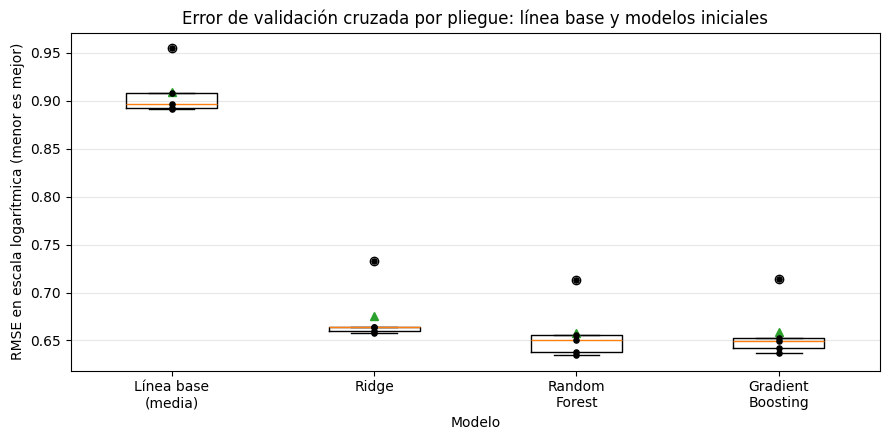

Comparación pareada contra la línea base (pliegue a pliegue):


,RMSE_log (val.),RMSE_log línea base,Reducción del RMSE vs. línea base (%),Pliegues en que supera a la base,Justifica su existencia
Modelo,,,,,
Ridge (inicial),0.676,0.909,25.669,5 de 5,Sí
Random Forest (inicial),0.658,0.909,27.586,5 de 5,Sí
Gradient Boosting (Hist) (inicial),0.659,0.909,27.473,5 de 5,Sí


In [25]:
# Distribución del RMSE_log por pliegue: línea base y modelos iniciales.
nombres_graf = [NOMBRE_BASE] + NOMBRES_INICIALES
etiquetas = ["Línea base\n(media)", "Ridge", "Random\nForest", "Gradient\nBoosting"]
datos = [RESULTADOS[n][0]["RMSE_log"].values for n in nombres_graf]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(datos, showmeans=True)
ax.set_xticklabels(etiquetas)
for i, d in enumerate(datos, start=1):
    ax.scatter(np.full(len(d), i), d, color="black", s=14, zorder=3)
ax.set_title("Error de validación cruzada por pliegue: línea base y modelos iniciales")
ax.set_xlabel("Modelo")
ax.set_ylabel("RMSE en escala logarítmica (menor es mejor)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Comparación pareada contra la línea base (pliegue a pliegue):")
display(reporte_vs_base(NOMBRES_INICIALES))

## 7.4 Lectura de los modelos iniciales

Para leer las tablas anteriores:

1. **Contra la línea base:** la columna "Justifica su existencia" resume el criterio de la sección 6.4. Un modelo con "NO" no pasa a la Actividad 7 sin una explicación.
2. **Brecha entre entrenamiento y validación:** `Brecha RMSE (val. − entren.)` mide cuánto peor predice el modelo a personas que no vio. Una brecha cercana a cero indica poco sobreajuste; una brecha grande, que el modelo memoriza parte del entrenamiento. Se espera que **Random Forest** muestre más brecha que Ridge, porque sus árboles profundos pueden ajustar casi todo el entrenamiento; el error de *entrenamiento* sobre el entrenamiento completo (tabla de la sección 7.3) es optimista por esa misma razón y **no** debe presentarse como desempeño del modelo.
3. **Variabilidad entre pliegues:** el desvío entre pliegues da una idea de cuánto depende el resultado de qué personas caen en la validación. Diferencias entre modelos menores que ese desvío no son concluyentes.
4. **Escala en guaraníes:** `MAE_Gs` y `MdAPE` permiten comunicar el error en términos de ingreso; `MAPE` y `RMSE_Gs` se leen con las salvedades de la sección 6.3.

Los modelos iniciales **no se eligen ni se descartan todavía**: la Actividad 6 mejora su configuración con una búsqueda de hiperparámetros, y la comparación definitiva se hace con los modelos ajustados.

# 8. Actividad 6 — Validación cruzada y ajuste de hiperparámetros

## 8.1 Diseño de la búsqueda

| Elemento | Decisión |
|---|---|
| **Datos usados** | Solo `X_train`, `y_train` y los pliegues de la sección 6.2. **`X_test` e `y_test` no se pasan a ninguna búsqueda ni se usan para decidir nada.** |
| **Validación** | Los mismos 5 pliegues agrupados por hogar y estratificados por deciles del objetivo (comparaciones pareadas). |
| **Métrica de optimización** | `RMSE_log` (`neg_root_mean_squared_error` en scikit-learn), la misma métrica de decisión de la sección 6.3. |
| **Sin fuga de información** | El preprocesador está dentro del `Pipeline`, por lo que imputaciones, escalado y codificación se reajustan en cada pliegue. |
| **Ridge** | **Búsqueda en grilla** (`GridSearchCV`): un solo hiperparámetro, espacio pequeño, se puede recorrer completo. |
| **Random Forest y Gradient Boosting** | **Búsqueda aleatoria** (`RandomizedSearchCV`) con número de iteraciones fijo y `random_state = SEMILLA`: con 3 a 5 hiperparámetros, una grilla completa tendría cientos de combinaciones y la búsqueda aleatoria explora el espacio de forma más eficiente. |
| **Reajuste** | `refit=True`: la mejor configuración se reajusta con **todo el entrenamiento**. Aún no se evalúa en prueba. |
| **Control del sobreajuste** | Se guardan también los errores de ajuste (`return_train_score=True`) para ver la brecha de cada configuración, no solo la del ganador. |

## 8.2 Espacios de búsqueda

Los espacios son amplios alrededor de los valores iniciales de la sección 7.2, y se incluyen configuraciones **más simples** (árboles poco profundos, hojas grandes, más regularización) y **más complejas**, porque lo que se busca es el punto óptimo del equilibrio entre sesgo y varianza.

| Modelo | Hiperparámetro | Valores explorados |
|---|---|---|
| Ridge | `alpha` | 0,001; 0,01; 0,1; 1; 10; 100; 1000 |
| Random Forest | `max_depth` | 6; 10; 14; 20; sin límite |
| | `min_samples_leaf` | 1; 3; 5; 10; 20; 40 |
| | `max_features` | 0,3; 0,5; 0,7; 1,0 |
| | `n_estimators` | **fijo en 300** (más árboles no sobreajustan, solo cuestan tiempo; no es un hiperparámetro a optimizar) |
| Gradient Boosting | `learning_rate` | 0,02; 0,05; 0,1; 0,2 |
| | `max_iter` | 100; 200; 400; 600 |
| | `max_leaf_nodes` | 8; 15; 31; 63 |
| | `min_samples_leaf` | 10; 20; 50; 100 |
| | `l2_regularization` | 0; 0,1; 1; 10 |

**Advertencia de tiempo:** la búsqueda del Random Forest y la del Gradient Boosting pueden tardar **varios minutos** según el equipo .

In [27]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

ESPACIOS = {
    "Ridge": {
        "tipo": "grilla",
        "params": {"modelo__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    },
    "Random Forest": {
        "tipo": "aleatoria", "n_iter": 20,
        "params": {
            "modelo__max_depth": [6, 10, 14, 20, None],
            "modelo__min_samples_leaf": [1, 3, 5, 10, 20, 40],
            "modelo__max_features": [0.3, 0.5, 0.7, 1.0],
        },
    },
    "Gradient Boosting (Hist)": {
        "tipo": "aleatoria", "n_iter": 30,
        "params": {
            "modelo__learning_rate": [0.02, 0.05, 0.1, 0.2],
            "modelo__max_iter": [100, 200, 400, 600],
            "modelo__max_leaf_nodes": [8, 15, 31, 63],
            "modelo__min_samples_leaf": [10, 20, 50, 100],
            "modelo__l2_regularization": [0.0, 0.1, 1.0, 10.0],
        },
    },
}

def correr_busqueda(nombre, pipe, cfg, n_jobs):
    comunes = dict(scoring="neg_root_mean_squared_error", cv=cv_pliegues, refit=True,
                   return_train_score=True, n_jobs=n_jobs)
    if cfg["tipo"] == "grilla":
        bus = GridSearchCV(pipe, cfg["params"], **comunes)
    else:
        bus = RandomizedSearchCV(pipe, cfg["params"], n_iter=cfg["n_iter"], random_state=SEMILLA, **comunes)
    t0 = time.time()
    bus.fit(X_train, y_train)               # solo entrenamiento; la prueba no entra
    n_comb = len(bus.cv_results_["params"])
    print(f"{nombre}: {n_comb} configuraciones x {N_PLIEGUES} pliegues en {time.time() - t0:.0f} s | "
          f"mejor RMSE_log de validación = {-bus.best_score_:.4f}")
    return bus

modelos_base = construir_modelos()
BUSQUEDAS = {}

# Ridge: grilla (rápida).
BUSQUEDAS["Ridge"] = correr_busqueda("Ridge", modelos_base["Ridge"], ESPACIOS["Ridge"], n_jobs=-1)

# Random Forest: paraleliza la búsqueda (un procesador por árbol-bosque) para no sobresaturar el equipo.
rf = modelos_base["Random Forest"].set_params(modelo__n_jobs=1)
BUSQUEDAS["Random Forest"] = correr_busqueda("Random Forest", rf, ESPACIOS["Random Forest"], n_jobs=-1)

# Gradient Boosting: ya usa varios hilos internamente; la búsqueda se hace en serie.
BUSQUEDAS["Gradient Boosting (Hist)"] = correr_busqueda(
    "Gradient Boosting (Hist)", modelos_base["Gradient Boosting (Hist)"], ESPACIOS["Gradient Boosting (Hist)"], n_jobs=1)

Ridge: 7 configuraciones x 5 pliegues en 9 s | mejor RMSE_log de validación = 0.6756
Random Forest: 20 configuraciones x 5 pliegues en 374 s | mejor RMSE_log de validación = 0.6448
Gradient Boosting (Hist): 30 configuraciones x 5 pliegues en 284 s | mejor RMSE_log de validación = 0.6440


## 8.3 Resultados de la búsqueda

Para cada modelo se muestran las cinco mejores configuraciones con su error de validación, su desvío entre pliegues y su error de ajuste. Si el error de ajuste es mucho menor que el de validación en las mejores configuraciones, el modelo sigue sobreajustando incluso en su punto óptimo.

In [28]:
def tabla_busqueda(bus, n=5):
    r = pd.DataFrame(bus.cv_results_)
    out = pd.DataFrame({
        "parámetros": r["params"].apply(lambda d: ", ".join(f"{k.replace('modelo__', '')}={v}" for k, v in d.items())),
        "RMSE_log (val.)": -r["mean_test_score"],
        "± desvío": r["std_test_score"],
        "RMSE_log (ajuste)": -r["mean_train_score"],
    })
    out["Brecha"] = out["RMSE_log (val.)"] - out["RMSE_log (ajuste)"]
    return out.assign(ranking=r["rank_test_score"]).sort_values("ranking").head(n).set_index("ranking")

for nombre, bus in BUSQUEDAS.items():
    print(f"\n=== {nombre} — mejores configuraciones ===")
    with pd.option_context("display.max_colwidth", None, "display.width", 200):
        display(tabla_busqueda(bus))
    # Historial completo de la búsqueda, para reproducir y auditar.
    pd.DataFrame(bus.cv_results_).drop(columns=["params"]).to_csv(
        DIR_SALIDA / f"busqueda_{re.sub(r'[^a-z0-9]+', '_', nombre.lower()).strip('_')}.csv", index=False)

# Mejores hiperparámetros: se documentan y se guardan.
MEJORES_HP = {n: {k.replace("modelo__", ""): v for k, v in b.best_params_.items()} for n, b in BUSQUEDAS.items()}
with open(DIR_SALIDA / "mejores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump(MEJORES_HP, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("\nMejores hiperparámetros (guardados en output/fase3/mejores_hiperparametros.json):")
display(pd.DataFrame({n: pd.Series(d, dtype=object) for n, d in MEJORES_HP.items()}).fillna("—"))

# ¿Algún ganador quedó en el borde del espacio explorado? Si es así, conviene ampliar el espacio.
print("\nControl de bordes del espacio de búsqueda:")
alguno = False
for nombre, bus in BUSQUEDAS.items():
    for p, valores in ESPACIOS[nombre]["params"].items():
        mejor = bus.best_params_[p]
        if len(valores) > 2 and (mejor == valores[0] or mejor == valores[-1]):
            alguno = True
            extremo = "mínimo" if mejor == valores[0] else "máximo"
            print(f"  - {nombre}: {p.replace('modelo__', '')} = {mejor} está en el {extremo} del rango explorado "
                  f"({valores[0]} … {valores[-1]}).")
if not alguno:
    print("  Ningún hiperparámetro ganador está en el borde de su rango.")


=== Ridge — mejores configuraciones ===


,parámetros,RMSE_log (val.),± desvío,RMSE_log (ajuste),Brecha
ranking,,,,,
1,alpha=1,0.676,0.029,0.675,0.000
2,alpha=0.1,0.676,0.029,0.675,0.000
3,alpha=0.01,0.676,0.029,0.675,0.000
4,alpha=0.001,0.676,0.029,0.675,0.000
5,alpha=10,0.676,0.029,0.675,0.000



=== Random Forest — mejores configuraciones ===


,parámetros,RMSE_log (val.),± desvío,RMSE_log (ajuste),Brecha
ranking,,,,,
1,"min_samples_leaf=5, max_features=0.3, max_depth=10",0.645,0.030,0.606,0.039
2,"min_samples_leaf=20, max_features=0.7, max_depth=10",0.645,0.029,0.619,0.027
3,"min_samples_leaf=20, max_features=0.7, max_depth=20",0.645,0.029,0.614,0.032
4,"min_samples_leaf=20, max_features=0.7, max_depth=14",0.646,0.029,0.614,0.031
5,"min_samples_leaf=40, max_features=0.7, max_depth=20",0.648,0.029,0.631,0.017



=== Gradient Boosting (Hist) — mejores configuraciones ===


,parámetros,RMSE_log (val.),± desvío,RMSE_log (ajuste),Brecha
ranking,,,,,
1,"min_samples_leaf=100, max_leaf_nodes=31, max_iter=100, learning_rate=0.05, l2_regularization=1.0",0.644,0.029,0.622,0.022
2,"min_samples_leaf=100, max_leaf_nodes=63, max_iter=200, learning_rate=0.02, l2_regularization=0.0",0.645,0.029,0.617,0.028
3,"min_samples_leaf=50, max_leaf_nodes=15, max_iter=100, learning_rate=0.1, l2_regularization=10.0",0.645,0.029,0.624,0.022
4,"min_samples_leaf=50, max_leaf_nodes=15, max_iter=100, learning_rate=0.05, l2_regularization=0.0",0.645,0.030,0.632,0.014
5,"min_samples_leaf=10, max_leaf_nodes=31, max_iter=200, learning_rate=0.02, l2_regularization=0.1",0.646,0.029,0.617,0.029



Mejores hiperparámetros (guardados en output/fase3/mejores_hiperparametros.json):


,Ridge,Random Forest,Gradient Boosting (Hist)
alpha,1,—,—
l2_regularization,—,—,1.000
learning_rate,—,—,0.050
max_depth,—,10,—
max_features,—,0.300,—
max_iter,—,—,100
max_leaf_nodes,—,—,31
min_samples_leaf,—,5,100



Control de bordes del espacio de búsqueda:
  - Random Forest: max_features = 0.3 está en el mínimo del rango explorado (0.3 … 1.0).
  - Gradient Boosting (Hist): max_iter = 100 está en el mínimo del rango explorado (100 … 600).
  - Gradient Boosting (Hist): min_samples_leaf = 100 está en el máximo del rango explorado (10 … 100).


## 8.4 Validación cruzada de los modelos ajustados y comparación final

Los modelos ajustados se vuelven a evaluar con la validación cruzada completa para obtener **todas** las métricas (la búsqueda solo optimizó `RMSE_log`) y compararlos, pliegue a pliegue, con la línea base y con los modelos iniciales.

**Precaución sobre el optimismo:** el mejor puntaje de una búsqueda es el **máximo entre muchas configuraciones** evaluadas sobre los mismos pliegues; por eso es algo optimista respecto del desempeño real en personas nuevas. Esto es esperable y no es un error, pero implica que **el desempeño definitivo solo se puede informar con el conjunto de prueba, una única vez** (Actividad 7). Por esa razón no se vuelve a tocar ningún hiperparámetro después de este punto.

In [29]:
MODELOS_AJUSTADOS = {}      # pipelines con los mejores hiperparámetros, reajustados con TODO el entrenamiento (aún sin evaluar en prueba)
NOMBRES_AJUSTADOS = []

for nombre, bus in BUSQUEDAS.items():
    nombre_aj = f"{nombre} (ajustado)"
    MODELOS_AJUSTADOS[nombre] = bus.best_estimator_
    est = clone(bus.best_estimator_)
    if "n_jobs" in est.named_steps["modelo"].get_params():
        est.set_params(modelo__n_jobs=-1)      # el n_jobs=1 era solo para la búsqueda
    RESULTADOS[nombre_aj] = validar_cv(est, X_train, y_train, cv_pliegues, nombre_aj)
    NOMBRES_AJUSTADOS.append(nombre_aj)

NOMBRES_TODOS = [NOMBRE_BASE, "Línea base alternativa: mediana",
                 "Referencia (no es línea base): solo años de estudio"] + NOMBRES_INICIALES + NOMBRES_AJUSTADOS
tabla_final = resumen_modelos(NOMBRES_TODOS)
display(tabla_final)
tabla_final.to_csv(DIR_SALIDA / "resumen_validacion_cruzada.csv")

print("\nComparación pareada de los modelos ajustados contra la línea base:")
display(reporte_vs_base(NOMBRES_AJUSTADOS))

,RMSE_log (val.),± desvío entre pliegues,RMSE_log (entren.),Brecha RMSE (val. − entren.),MAE_log (val.),R² (val.),R² (entren.),MAE_Gs (val.),MdAPE % (val.),MAPE % (val.)
Modelo,,,,,,,,,,
Línea base: media de ln(ingreso),0.909,0.027,0.909,-0.000,0.653,-0.000,0.000,"1,788,605.456",39.533,204.973
Línea base alternativa: mediana,0.924,0.027,0.925,-0.000,0.630,-0.035,-0.035,"1,736,378.559",35.572,240.188
Referencia (no es línea base): solo años de estudio,0.845,0.024,0.845,-0.000,0.601,0.135,0.136,"1,648,974.924",39.676,170.945
Ridge (inicial),0.676,0.032,0.675,0.000,0.472,0.447,0.448,"1,397,020.560",33.291,97.347
Random Forest (inicial),0.658,0.032,0.529,0.129,0.448,0.475,0.661,"1,323,711.172",29.803,87.874
Gradient Boosting (Hist) (inicial),0.659,0.031,0.552,0.108,0.449,0.474,0.632,"1,319,744.120",29.460,89.008
Ridge (ajustado),0.676,0.032,0.675,0.000,0.472,0.447,0.448,"1,397,020.560",33.291,97.347
Random Forest (ajustado),0.645,0.033,0.606,0.039,0.436,0.497,0.556,"1,291,501.909",28.565,87.446
Gradient Boosting (Hist) (ajustado),0.644,0.033,0.622,0.022,0.437,0.498,0.532,"1,293,622.387",28.672,89.052



Comparación pareada de los modelos ajustados contra la línea base:


,RMSE_log (val.),RMSE_log línea base,Reducción del RMSE vs. línea base (%),Pliegues en que supera a la base,Justifica su existencia
Modelo,,,,,
Ridge (ajustado),0.676,0.909,25.669,5 de 5,Sí
Random Forest (ajustado),0.645,0.909,29.056,5 de 5,Sí
Gradient Boosting (Hist) (ajustado),0.644,0.909,29.140,5 de 5,Sí


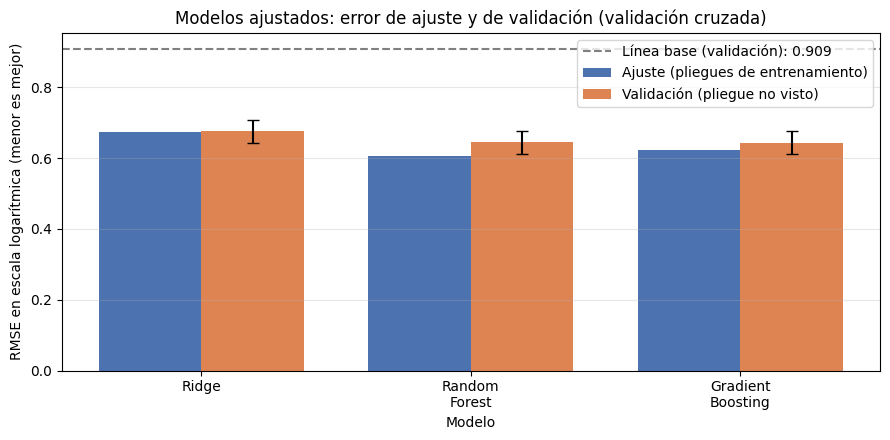

Mejor modelo en validación cruzada (criterio: menor RMSE_log): Gradient Boosting (Hist) (ajustado) — RMSE_log = 0.6440, R² = 0.498, MAE = 1,293,622 Gs., MdAPE = 28.7 %.
Reducción del error respecto de la línea base: 29.1 %.
  Ridge (ajustado): el ajuste de hiperparámetros cambió el RMSE_log de validación en +0.0000 respecto de la configuración inicial.
  Random Forest (ajustado): el ajuste de hiperparámetros cambió el RMSE_log de validación en -0.0134 respecto de la configuración inicial.
  Gradient Boosting (Hist) (ajustado): el ajuste de hiperparámetros cambió el RMSE_log de validación en -0.0152 respecto de la configuración inicial.


In [30]:
# Brecha entre error de ajuste y de validación de los modelos ajustados (diagnóstico de sobreajuste).
filas_graf = [(n.replace(" (ajustado)", ""),
               RESULTADOS[n][1]["RMSE_log"].mean(), RESULTADOS[n][0]["RMSE_log"].mean(),
               RESULTADOS[n][0]["RMSE_log"].std()) for n in NOMBRES_AJUSTADOS]
etq = ["Ridge", "Random\nForest", "Gradient\nBoosting"]
aj = [f[1] for f in filas_graf]; va = [f[2] for f in filas_graf]; sd = [f[3] for f in filas_graf]
base_rmse = RESULTADOS[NOMBRE_BASE][0]["RMSE_log"].mean()

x = np.arange(len(etq)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w/2, aj, w, label="Ajuste (pliegues de entrenamiento)", color="#4C72B0")
ax.bar(x + w/2, va, w, yerr=sd, capsize=4, label="Validación (pliegue no visto)", color="#DD8452")
ax.axhline(base_rmse, color="gray", linestyle="--", label=f"Línea base (validación): {base_rmse:.3f}")
ax.set_xticks(x); ax.set_xticklabels(etq)
ax.set_title("Modelos ajustados: error de ajuste y de validación (validación cruzada)")
ax.set_xlabel("Modelo")
ax.set_ylabel("RMSE en escala logarítmica (menor es mejor)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Veredicto calculado a partir de los resultados (no escrito a mano).
mejor = min(NOMBRES_AJUSTADOS, key=lambda n: RESULTADOS[n][0]["RMSE_log"].mean())
rm_mejor = RESULTADOS[mejor][0]["RMSE_log"].mean()
print(f"Mejor modelo en validación cruzada (criterio: menor RMSE_log): {mejor} — RMSE_log = {rm_mejor:.4f}, "
      f"R² = {RESULTADOS[mejor][0]['R2'].mean():.3f}, MAE = {RESULTADOS[mejor][0]['MAE_Gs'].mean():,.0f} Gs., "
      f"MdAPE = {RESULTADOS[mejor][0]['MdAPE_%'].mean():.1f} %.")
print(f"Reducción del error respecto de la línea base: {(1 - rm_mejor / base_rmse) * 100:.1f} %.")
for n in NOMBRES_AJUSTADOS:
    ini = n.replace("(ajustado)", "(inicial)")
    d = RESULTADOS[n][0]["RMSE_log"].mean() - RESULTADOS[ini][0]["RMSE_log"].mean()
    print(f"  {n}: el ajuste de hiperparámetros cambió el RMSE_log de validación en {d:+.4f} respecto de la configuración inicial.")

MODELO_SELECCIONADO = mejor.replace(" (ajustado)", "")

## 8.5 Cierre de las Actividades 4 a 6

- La **línea base** (media de `ln(ingreso)`) fija el piso de error; los criterios para superarla están en la sección 6.4.
- Se entrenaron **tres modelos de familias distintas** (lineal, árboles por *bagging* y *boosting*), con hiperparámetros iniciales documentados (sección 7.2) y mejorados por búsqueda en grilla o aleatoria con validación cruzada agrupada por hogar (sección 8).
- **El conjunto de prueba no se tocó** en ninguna de estas actividades: ni para la línea base, ni para entrenar, ni para decidir hiperparámetros. Sigue disponible para la **evaluación única de la Actividad 7**.
- Los tres modelos ajustados (`MODELOS_AJUSTADOS`) pasan a la Actividad 7. La variable `MODELO_SELECCIONADO` registra el mejor según validación cruzada, pero la comparación final entre los tres se informa en prueba.
- Archivos generados en `output/fase3/`: `hiperparametros_iniciales.json`, `busqueda_*.csv` (historial completo de cada búsqueda), `mejores_hiperparametros.json` y `resumen_validacion_cruzada.csv`.

# 9. Resumen de decisiones de las Actividades 1 a 6

In [31]:
resumen = pd.DataFrame({
    "Decisión": [
        "Tipo de tarea",
        "Variable objetivo",
        "Vínculo con el proyecto",
        "Base de modelado",
        "Predictores (lineal)",
        "Predictores (árboles)",
        "Codificación",
        "Escalado",
        "Desbalance de clases",
        "Partición",
        "Semilla",
        "Tamaño entrenamiento / prueba",
        "Línea base",
        "Validación cruzada",
        "Modelos (familias)",
        "Búsqueda de hiperparámetros",
        "Métrica de selección",
        "Mejores hiperparámetros (validación cruzada)",
    ],
    "Valor": [
        "Regresión",
        "ln(INGRESO_HABITUAL_PRINCIPAL)",
        "OE2 (principal), OE3 y OE4",
        f"Ocupados de 18-60 años con ingreso > 0 (n = {len(df_modelo):,})",
        ", ".join(NUM_LINEAL + BINARIAS + CATEGORICAS),
        ", ".join(NUM_ARBOLES + BINARIAS + CATEGORICAS),
        "Binarias 0/1; one-hot para categoría ocupacional (faltantes = 'sin_dato')",
        "StandardScaler solo en el preprocesador lineal",
        "No aplica (objetivo continuo)",
        "No temporal (corte transversal); 80/20 agrupada por hogar y estratificada por deciles del objetivo",
        str(SEMILLA),
        f"{len(X_train):,} / {len(X_test):,}",
        "Media de ln(ingreso) del entrenamiento (DummyRegressor); mediana como alternativa; referencia: solo años de estudio",
        f"{N_PLIEGUES} pliegues dentro del entrenamiento, agrupados por hogar y estratificados por deciles del objetivo",
        "Ridge (lineal) · Random Forest (árboles, bagging) · HistGradientBoosting (boosting)",
        f"Grilla (Ridge); aleatoria: Random Forest {ESPACIOS['Random Forest']['n_iter']} y Gradient Boosting {ESPACIOS['Gradient Boosting (Hist)']['n_iter']} configuraciones",
        "RMSE en escala logarítmica, validación cruzada (la prueba no se usa)",
        "; ".join(f"{n}: {d}" for n, d in MEJORES_HP.items()),
    ],
})
with pd.option_context("display.max_colwidth", None):
    display(resumen)

,Decisión,Valor
0,Tipo de tarea,Regresión
1,Variable objetivo,ln(INGRESO_HABITUAL_PRINCIPAL)
2,Vínculo con el proyecto,"OE2 (principal), OE3 y OE4"
3,Base de modelado,"Ocupados de 18-60 años con ingreso > 0 (n = 22,773)"
4,Predictores (lineal),"ANIOS_ESTUDIO, EDAD, EDAD2, HORAS_SEMANALES_PRINCIPAL, ANIOS_X_MUJER, ANIOS_X_RURAL, SEXO_MUJER, AREA_RURAL, INFORMAL, CATEGORIA_OCUPACIONAL_CAT"
5,Predictores (árboles),"ANIOS_ESTUDIO, EDAD, HORAS_SEMANALES_PRINCIPAL, SEXO_MUJER, AREA_RURAL, INFORMAL, CATEGORIA_OCUPACIONAL_CAT"
6,Codificación,Binarias 0/1; one-hot para categoría ocupacional (faltantes = 'sin_dato')
7,Escalado,StandardScaler solo en el preprocesador lineal
8,Desbalance de clases,No aplica (objetivo continuo)
9,Partición,No temporal (corte transversal); 80/20 agrupada por hogar y estratificada por deciles del objetivo


## Notas y limitaciones de esta etapa

- **Alcance del modelo:** ocupados de 18 a 60 años **con ingreso laboral positivo**; no describe a desocupados, inactivos, trabajadores sin ingreso ni mayores de 60 años.
- **Faltantes en predictores:** se imputan con estadísticos del entrenamiento. Si la tabla de faltantes muestra una proporción relevante en alguna variable, conviene evaluar un indicador de faltante.
- **Interacciones:** `ANIOS_X_MUJER` se apoya en H4; `ANIOS_X_RURAL` es exploratoria, porque la Fase 2 no contrastó esa hipótesis.
- **Ponderación muestral:** no se pondera por `FACTOR_EXPANSION`, igual que en la Fase 2. Las métricas describen a la muestra, no a la población del país.
- **Escala en guaraníes:** `exp(predicción)` estima la mediana condicional del ingreso y no su media; `MAPE` es inestable por los ingresos muy pequeños, por eso se acompaña de `MdAPE` (sección 6.3).
- **Optimismo de la búsqueda:** el mejor puntaje de validación cruzada es algo optimista por haber sido elegido entre muchas configuraciones; el desempeño definitivo se informa solo en prueba (Actividad 7).
- **Espacios de búsqueda acotados:** la búsqueda aleatoria explora una parte del espacio; el control de bordes de la sección 8.3 indica si conviene ampliarlo.
- **Próximas actividades:** evaluación única en prueba (7), análisis de errores (8) e interpretación del modelo (9).

## Declaración de uso de asistencia de IA
Se utilizó un asistente de IA como apoyo en la estructuración del notebook, la redacción y la depuración de código. Las decisiones metodológicas (tarea, variable objetivo, tratamiento de ceros, criterio de partición y selección de variables) son revisadas y asumidas por el grupo.